# 🌿 Proyecto Final de Machine Learning
## Clasificación Inteligente de Residuos Sólidos
**Maestría en IA, Educación e Investigación | Curso: Machine Learning**  
**Fecha:** Noviembre 2026  
**Autor:** Estudiante  
**Dataset:** [Unified Waste Classification Dataset (Kaggle)](https://www.kaggle.com/datasets/siddhantmaji/unified-waste-classification-dataset)

---

## 📑 Tabla de Contenido

1. [Sumario Ejecutivo](#sumario)
2. [Contextualización del Problema](#contexto)
3. [Instalación e Importación de Librerías](#instalacion)
4. [Ingesta de Datos desde Kaggle](#ingesta)
5. [ETL: Extracción, Transformación y Carga](#etl)
6. [EDA: Análisis Exploratorio de Datos](#eda)
7. [Data Profiling Automatizado](#profiling)
8. [Preparación de Datos para Modelado](#preparacion)
9. [Modelado: Clasificación Supervisada](#modelado)
10. [Evaluación y Métricas](#evaluacion)
11. [Predicciones sobre Nuevas Muestras](#predicciones)
12. [Diccionario de Variables](#variables)
13. [Simulador Interactivo en HTML](#simulador)
14. [Conclusiones](#conclusiones)
15. [Referencias](#referencias)

## 🧭 1. Sumario Ejecutivo

Este proyecto desarrolla un **prototipo de Machine Learning** orientado a la **clasificación automática de residuos sólidos** a partir de imágenes, con el propósito de apoyar procesos de separación, reciclaje y gestión ambiental.

Se parte del dataset *Unified Waste Classification Dataset* de Kaggle, del cual se extraen características visuales (color promedio, intensidad, textura) para construir un conjunto de datos tabular que permita aplicar algoritmos de clasificación supervisada clásicos: **Regresión Logística, Random Forest y Support Vector Machine (SVM)**.

El flujo completo incluye:
- ⬇️ Ingesta automatizada con `kagglehub`.
- 🧹 ETL con extracción de características de imagen.
- 📊 EDA con visualizaciones y estadísticas descriptivas.
- 📈 Data Profiling con `ydata-profiling`.
- 🤖 Entrenamiento, evaluación y comparación de modelos.
- 🎯 Predicciones y simulador interactivo en HTML.

El objetivo es entregar un ejercicio **funcional, reproducible, documentado y desplegable**, alineado con los criterios de la guía del curso.

## 🌎 2. Contextualización del Problema

### 2.1 Problema
La gestión inadecuada de residuos sólidos es uno de los principales desafíos ambientales. La clasificación manual es lenta, propensa a errores y costosa.

### 2.2 Pregunta de investigación
*¿Es posible clasificar automáticamente residuos sólidos en categorías como orgánico, plástico, papel, vidrio y metal a partir de características visuales extraídas de imágenes, usando modelos de Machine Learning supervisado?*

### 2.3 Objetivo general
Desarrollar un clasificador de residuos que combine extracción de características, modelado supervisado y una interfaz interactiva para demostrar su utilidad práctica.

### 2.4 Objetivos específicos
1. Descargar y explorar el dataset de Kaggle.
2. Aplicar un pipeline ETL que convierta imágenes en un dataset tabular.
3. Realizar EDA y Data Profiling.
4. Entrenar y comparar al menos tres modelos de clasificación.
5. Evaluar con métricas apropiadas (Accuracy, Precision, Recall, F1, ROC-AUC).
6. Construir un simulador HTML para probar el modelo.
7. Documentar y concluir.

## ⚙️ 3. Instalación e Importación de Librerías

Instalamos las dependencias necesarias y cargamos las librerías para manipulación de datos, visualización, procesamiento de imágenes y modelado.

In [ ]:
# Instalación de librerías (ejecutar solo la primera vez)
!pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn
!pip install -q Pillow ydata-profiling ipywidgets

In [ ]:
# Instalar dependencias necesarias para ydata-profiling en esta sesión
!pip install -U ydata-profiling

In [ ]:
!pip install -q Pillow ydata-profiling ipywidgets

In [ ]:
import os
# Forzar el reinicio inmediato del entorno de ejecución
os._exit(0)

In [ ]:
# Importación de librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_auc_score)

# Data Profiling
try:
    from ydata_profiling import ProfileReport
    PROFILING_AVAILABLE = True
except ImportError:
    PROFILING_AVAILABLE = False
    print("⚠️ 'ydata-profiling' no pudo ser importada. Intenta reiniciar el entorno de ejecución.")

# Visualización
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('✅ Librerías cargadas correctamente.')

✅ Librerías cargadas correctamente.


/tmp/ipykernel_9241/2239818870.py:22: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## ⬇️ 4. Ingesta de Datos desde Kaggle

Utilizamos `kagglehub` para descargar la versión más reciente del dataset *Unified Waste Classification Dataset*.

In [ ]:
import kagglehub

# Descarga del dataset (rápida si ya está en caché)
path = kagglehub.dataset_download('siddhantmaji/unified-waste-classification-dataset')
print('📁 Ruta del dataset:', path)

Using Colab cache for faster access to the 'unified-waste-classification-dataset' dataset.
📁 Ruta del dataset: /kaggle/input/unified-waste-classification-dataset


In [ ]:
from pathlib import Path

# Exploración de la estructura de carpetas
data_path = Path(path)

# Listar subdirectorios (categorías de residuos)
categories = [d.name for d in data_path.iterdir() if d.is_dir()]
print(f'🗂️  Se encontraron {len(categories)} categorías de residuos:')
for c in categories:
    print(f'  • {c}')

🗂️  Se encontraron 1 categorías de residuos:
  • content


## 🧹 5. ETL: Extracción, Transformación y Carga

Como el dataset contiene imágenes, realizamos un proceso de **extracción de características** para convertir cada imagen en un registro tabular con variables numéricas que los modelos clásicos puedan procesar.

**Características extraídas por imagen:**
- `mean_r`, `mean_g`, `mean_b`: promedio de los canales RGB.
- `std_r`, `std_g`, `std_b`: desviación estándar de los canales.
- `brightness`: brillo promedio.
- `contrast`: contraste (desviación de la escala de grises).
- `aspect_ratio`: relación de aspecto (ancho/alto).
- `categoria`: etiqueta objetivo (target).

In [ ]:
def extract_features(img_path):
    """
    Extrae características visuales de una imagen.
    Retorna un diccionario con las variables numéricas.
    """
    try:
        img = Image.open(img_path).convert('RGB')
        img_array = np.array(img)

        # Canales RGB
        r, g, b = img_array[:,:,0], img_array[:,:,1], img_array[:,:,2]

        # Escala de grises para brillo y contraste
        gray = np.mean(img_array, axis=2)

        features = {
            'mean_r': np.mean(r),
            'mean_g': np.mean(g),
            'mean_b': np.mean(b),
            'std_r': np.std(r),
            'std_g': np.std(g),
            'std_b': np.std(b),
            'brightness': np.mean(gray),
            'contrast': np.std(gray),
            'aspect_ratio': img.width / img.height
        }
        return features
    except Exception as e:
        print(f'⚠️ Error procesando {img_path}: {e}')
        return None

print('✅ Función de extracción definida.')

✅ Función de extracción definida.


In [ ]:
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

data_path = Path(path)

# Aseguramos la definición de la función de extracción de características
def extract_features(img_path):
    try:
        img = Image.open(img_path).convert('RGB')
        img_array = np.array(img)

        # Canales RGB
        r, g, b = img_array[:,:,0], img_array[:,:,1], img_array[:,:,2]

        # Escala de grises para brillo y contraste
        gray = np.mean(img_array, axis=2)

        features = {
            'mean_r': np.mean(r),
            'mean_g': np.mean(g),
            'mean_b': np.mean(b),
            'std_r': np.std(r),
            'std_g': np.std(g),
            'std_b': np.std(b),
            'brightness': np.mean(gray),
            'contrast': np.std(gray),
            'aspect_ratio': img.width / img.height
        }
        return features
    except Exception as e:
        print(f'⚠️ Error procesando {img_path}: {e}')
        return None

# Construcción del dataset tabular
records = []
MAX_IMAGES_PER_CLASS = 150  # Limitamos para que el tutorial sea ejecutable

# Buscamos todas las carpetas que contienen directamente archivos de imagen
valid_extensions = {'.jpg', '.jpeg', '.png'}
possible_dirs = [d for d in data_path.rglob('*') if d.is_dir()]

# Filtramos para quedarnos con carpetas de categorías reales
categories_dirs = []
for d in possible_dirs:
    if d.exists() and any(f.suffix.lower() in valid_extensions for f in d.iterdir() if f.is_file()):
        categories_dirs.append(d)

print(f'🗂️ Se detectaron {len(categories_dirs)} carpetas de categorías reales:')
for d in categories_dirs:
    print(f'  • {d.name} (en {d.relative_to(data_path)})')

for category_dir in categories_dirs:
    category_name = category_dir.name
    image_files = [f for f in category_dir.iterdir() if f.suffix.lower() in valid_extensions]

    # Muestreo para eficiencia
    image_files = image_files[:MAX_IMAGES_PER_CLASS]

    for img_file in image_files:
        feats = extract_features(img_file)
        if feats:
            feats['categoria'] = category_name
            feats['archivo'] = img_file.name
            records.append(feats)

df = pd.DataFrame(records)
print(f'\n📊 Dataset construido: {df.shape[0]} imágenes × {df.shape[1]} variables')

🗂️ Se detectaron 8 carpetas de categorías reales:
  • metal (en content/unified_dataset/metal)
  • glass (en content/unified_dataset/glass)
  • organic_waste (en content/unified_dataset/organic_waste)
  • battery (en content/unified_dataset/battery)
  • trash (en content/unified_dataset/trash)
  • textiles (en content/unified_dataset/textiles)
  • paper_cardboard (en content/unified_dataset/paper_cardboard)
  • plastic (en content/unified_dataset/plastic)

📊 Dataset construido: 1200 imágenes × 11 variables


In [ ]:
# Vista preliminar del dataset
df.head()

,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,aspect_ratio,categoria,archivo
0,141.555465,116.202208,101.013632,70.336142,70.879107,57.975919,119.590435,65.135636,1.0,organic_waste,image_06319_hw.jpg
1,240.516342,232.612145,222.497270,31.075430,44.114294,62.297445,231.875252,44.736580,1.0,organic_waste,image_02665_aug.jpg
2,203.788744,185.292829,175.690330,67.280081,88.007907,95.314150,188.257301,81.023400,1.0,organic_waste,image_06823_hw.jpg
3,210.536113,197.248186,188.779955,47.040947,61.417302,75.748096,198.854751,59.343143,1.0,organic_waste,image_06744_hw.jpg
4,201.710180,177.651885,152.471600,37.792228,39.570103,47.536197,177.277888,37.299442,1.0,organic_waste,image_05469_aug.jpg


## 📊 6. EDA: Análisis Exploratorio de Datos

Analizamos la distribución de las variables, la balance de clases y las relaciones entre características.

In [ ]:
# Información general
df.info()
print('\n')
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mean_r        1200 non-null   float64
 1   mean_g        1200 non-null   float64
 2   mean_b        1200 non-null   float64
 3   std_r         1200 non-null   float64
 4   std_g         1200 non-null   float64
 5   std_b         1200 non-null   float64
 6   brightness    1200 non-null   float64
 7   contrast      1200 non-null   float64
 8   aspect_ratio  1200 non-null   float64
 9   categoria     1200 non-null   object 
 10  archivo       1200 non-null   object 
dtypes: float64(9), object(2)
memory usage: 103.3+ KB




,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,aspect_ratio
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.0
mean,164.065664,157.753061,148.986875,58.359908,58.116438,59.844201,156.935200,57.316335,1.0
std,49.427645,50.730117,55.148217,22.372105,21.723339,23.052452,50.323102,21.120380,0.0
min,1.383849,0.898996,0.554907,4.297086,3.176496,2.658012,0.945917,3.313546,1.0
25%,134.897964,126.558245,111.786168,41.637804,42.622843,42.707374,125.701536,41.995799,1.0
50%,169.562032,160.854343,151.307219,57.546515,57.919570,59.868494,160.140864,56.428208,1.0
75%,198.540268,194.090840,189.212427,75.056843,73.499161,76.597904,193.368994,71.827615,1.0
max,251.915159,250.700594,250.083068,118.256295,117.587215,117.029535,249.222171,112.265909,1.0


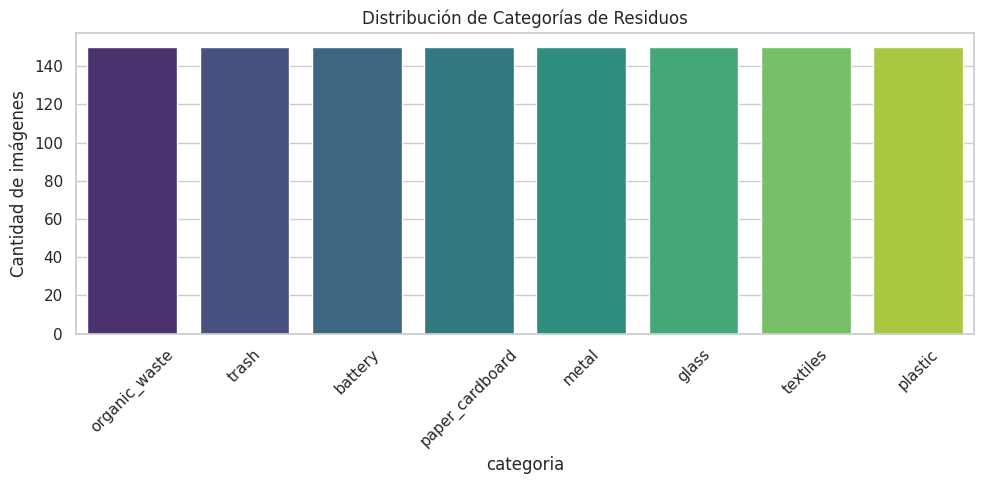

In [ ]:
# Distribución de clases
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='categoria', hue='categoria', palette='viridis', legend=False)
plt.title('Distribución de Categorías de Residuos')
plt.xticks(rotation=45)
plt.ylabel('Cantidad de imágenes')
plt.tight_layout()
plt.show()

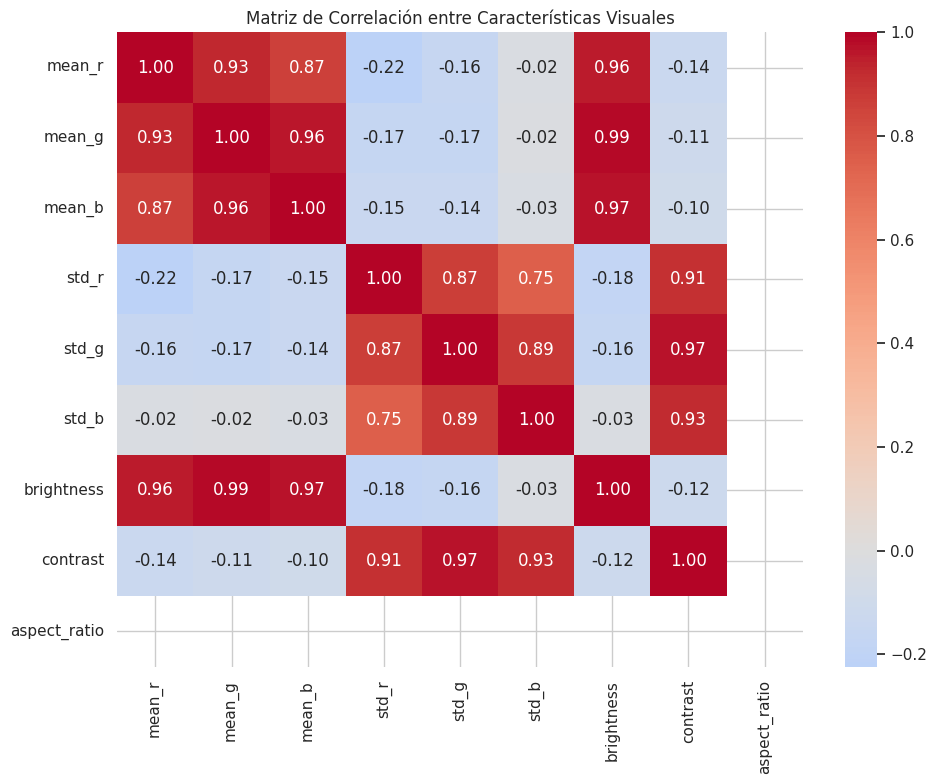

In [ ]:
# Matriz de correlación entre variables numéricas
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de Correlación entre Características Visuales')
plt.tight_layout()
plt.show()

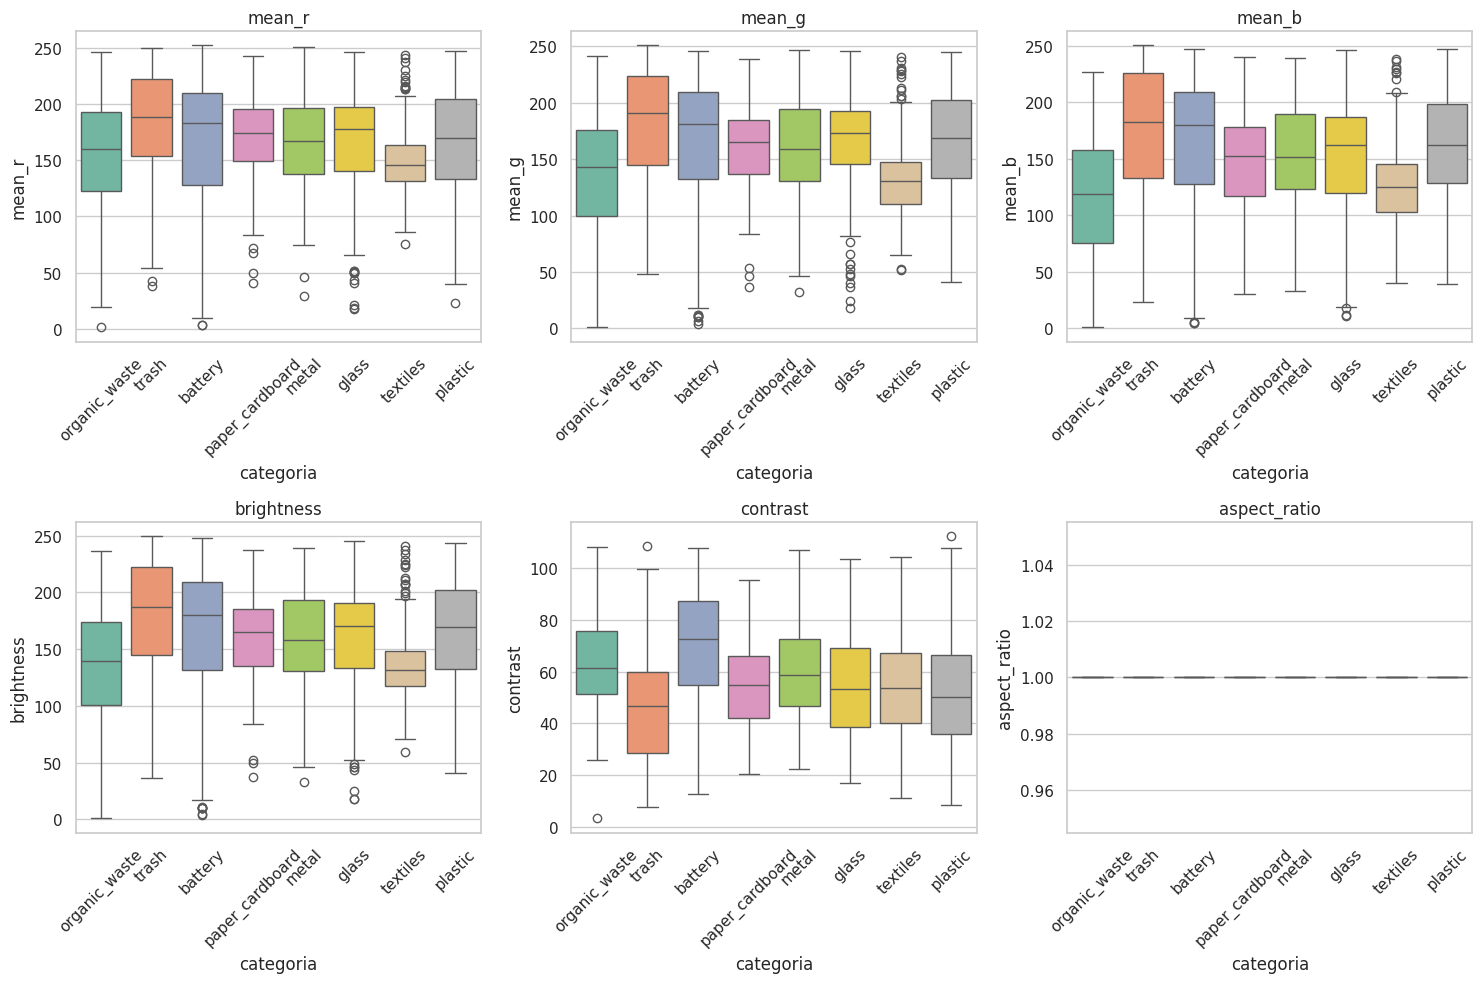

In [ ]:
# Boxplots de características por categoría
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
features_to_plot = ['mean_r', 'mean_g', 'mean_b', 'brightness', 'contrast', 'aspect_ratio']

for ax, feat in zip(axes.flatten(), features_to_plot):
    sns.boxplot(data=df, x='categoria', y=feat, ax=ax, hue='categoria', palette='Set2', legend=False)
    ax.set_title(feat)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 🔍 7. Data Profiling Automatizado

Generamos un **informe de Data Profiling** con `ydata-profiling`, que produce estadísticas detalladas, histogramas, correlaciones, valores faltantes y alertas de calidad.

In [ ]:
if PROFILING_AVAILABLE:
    # Generación del reporte de Data Profiling
    profile = ProfileReport(df, title='Data Profiling - Clasificación de Residuos',
                            explorative=True, minimal=False)

    # Exportar a HTML
    profile.to_file('data_profiling_residuos.html')
    print('✅ Reporte generado: data_profiling_residuos.html')
else:
    print("⚠️ El reporte no pudo ser generado porque 'ydata-profiling' no está disponible.")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 41.59it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Reporte generado: data_profiling_residuos.html


In [ ]:
# Mostrar resumen del perfil en el notebook
profile.to_notebook_iframe()

## 🛠️ 8. Preparación de Datos para Modelado

Separamos variables predictoras (X) de la variable objetivo (y), codificamos las etiquetas y dividimos en conjuntos de entrenamiento y prueba (80/20).

In [ ]:
# Definición de features y target
feature_cols = ['mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b',
                'brightness', 'contrast', 'aspect_ratio']

X = df[feature_cols].copy()
y = df['categoria'].copy()

# Codificación de la variable objetivo
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print('Clases detectadas:', list(le.classes_))
print(f'X shape: {X.shape} | y shape: {y_encoded.shape}')

Clases detectadas: ['battery', 'glass', 'metal', 'organic_waste', 'paper_cardboard', 'plastic', 'textiles', 'trash']
X shape: (1200, 9) | y shape: (1200,)


In [ ]:
# División train/test estratificada (evita data leakage y preserva proporciones)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f'Entrenamiento: {X_train.shape[0]} muestras')
print(f'Prueba: {X_test.shape[0]} muestras')

Entrenamiento: 960 muestras
Prueba: 240 muestras


In [ ]:
# Escalamiento de variables (importante para LogisticRegression y SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('✅ Escalamiento completado.')

✅ Escalamiento completado.


## 🤖 9. Modelado: Clasificación Supervisada

Entrenamos tres modelos de clasificación y los comparamos:

| Modelo | Tipo | Justificación |
|---|---|---|
| Regresión Logística | Lineal | Línea base interpretable |
| Random Forest | Ensemble | Robusto, no lineal, maneja bien características correlacionadas |
| SVM | Basado en márgenes | Efectivo en espacios de alta dimensionalidad |

In [ ]:
# Diccionario de modelos
models = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42, multi_class='ovr'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42)
}

results = {}

for name, model in models.items():
    print(f'\n🔧 Entrenando {name}...')
    # SVM y LR usan datos escalados; RF no lo requiere pero lo usamos para comparar
    X_tr = X_train_scaled if name != 'Random Forest' else X_train.values
    X_te = X_test_scaled if name != 'Random Forest' else X_test.values

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'X_test': X_te
    }


🔧 Entrenando Regresión Logística...

🔧 Entrenando Random Forest...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(



🔧 Entrenando SVM...


## 📈 10. Evaluación y Métricas

Calculamos métricas clave: Accuracy, Precision, Recall, F1-Score (macro) y ROC-AUC (one-vs-rest).

In [ ]:
metricas = []

for name, res in results.items():
    y_pred = res['y_pred']
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    # ROC-AUC multiclase
    try:
        y_prob = res['model'].predict_proba(res['X_test'])
        auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
    except Exception:
        auc = np.nan

    metricas.append({'Modelo': name, 'Accuracy': acc, 'Precision': prec,
                     'Recall': rec, 'F1-Score': f1, 'ROC-AUC': auc})

df_metricas = pd.DataFrame(metricas).round(4)
df_metricas

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.2875,0.2947,0.2875,0.2612,0.7221
1,Random Forest,0.3292,0.3330,0.3292,0.3232,0.7190
2,SVM,0.3500,0.3323,0.3500,0.3263,0.7303


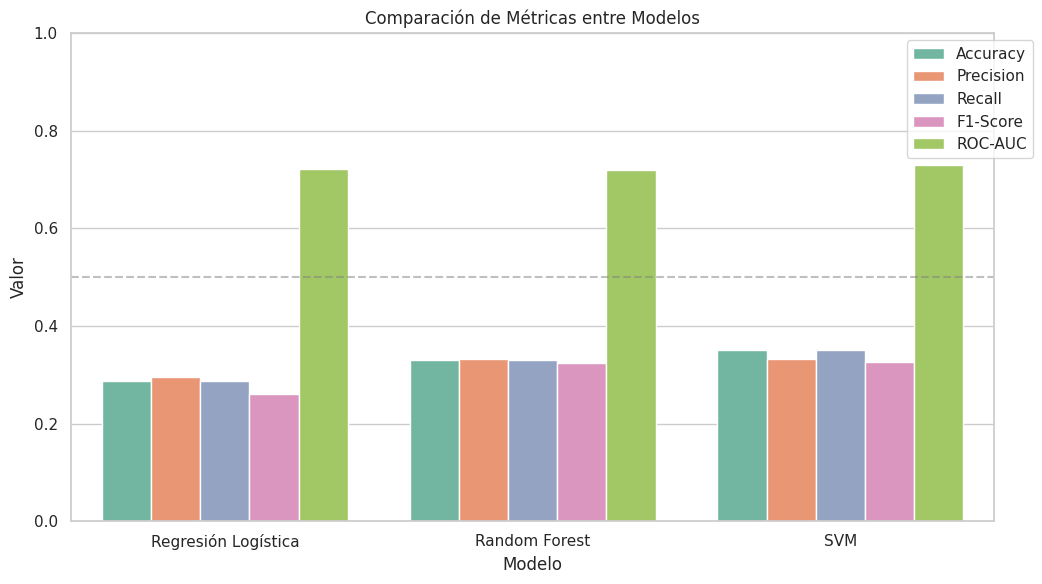

In [ ]:
# Visualización comparativa
df_plot = df_metricas.melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_plot, x='Modelo', y='Valor', hue='Métrica', palette='Set2')
plt.title('Comparación de Métricas entre Modelos')
plt.ylim(0, 1)
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [ ]:
# Selección del mejor modelo (por F1-Score macro)
best_model_name = df_metricas.loc[df_metricas['F1-Score'].idxmax(), 'Modelo']
best_model = results[best_model_name]['model']
print(f'🏆 Mejor modelo: {best_model_name}')

# Reporte detallado del mejor modelo
print('\n', classification_report(y_test, results[best_model_name]['y_pred'],
                                 target_names=le.classes_, zero_division=0))

🏆 Mejor modelo: SVM

                  precision    recall  f1-score   support

        battery       0.34      0.60      0.43        30
          glass       0.14      0.03      0.05        30
          metal       0.31      0.40      0.35        30
  organic_waste       0.65      0.57      0.61        30
paper_cardboard       0.26      0.23      0.25        30
        plastic       0.22      0.17      0.19        30
       textiles       0.37      0.57      0.45        30
          trash       0.37      0.23      0.29        30

       accuracy                           0.35       240
      macro avg       0.33      0.35      0.33       240
   weighted avg       0.33      0.35      0.33       240



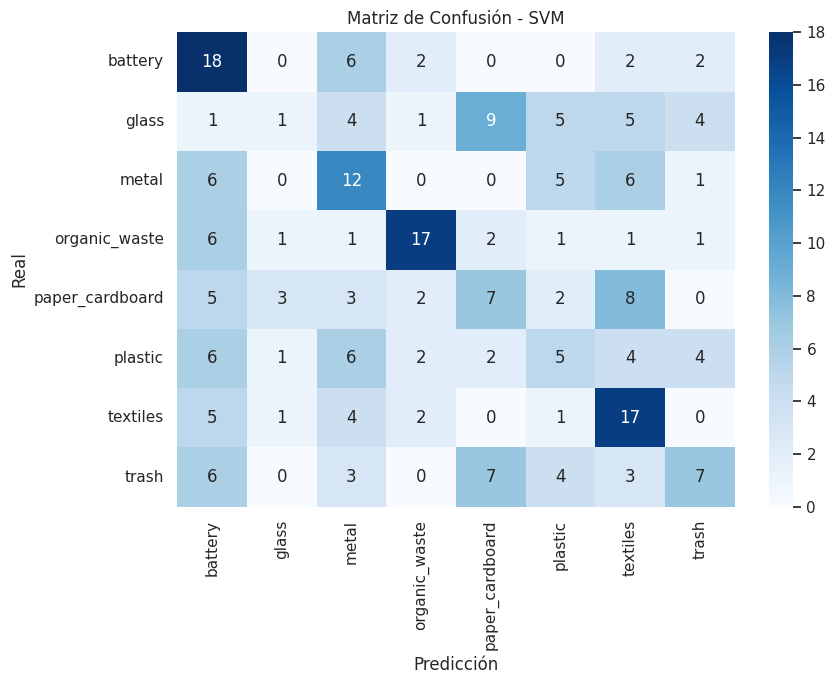

In [ ]:
# Matriz de confusión del mejor modelo
cm = confusion_matrix(y_test, results[best_model_name]['y_pred'])

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Matriz de Confusión - {best_model_name}')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

## 🎯 11. Predicciones sobre Nuevas Muestras

Simulamos la predicción sobre 5 muestras nuevas del conjunto de prueba.

In [ ]:
# Tomamos 5 muestras del test
sample_idx = np.random.choice(len(X_test), 5, replace=False)
X_sample = X_test.iloc[sample_idx]
y_sample_real = y_test[sample_idx]

# Predicción con el mejor modelo
if best_model_name != 'Random Forest':
    X_sample_proc = scaler.transform(X_sample)
else:
    X_sample_proc = X_sample.values

y_sample_pred = best_model.predict(X_sample_proc)
y_sample_prob = best_model.predict_proba(X_sample_proc)

# Tabla de predicciones
pred_df = pd.DataFrame({
    'Muestra': [f'Muestra {i+1}' for i in range(5)],
    'Categoría Real': le.inverse_transform(y_sample_real),
    'Categoría Predicha': le.inverse_transform(y_sample_pred),
    'Confianza (%)': (y_sample_prob.max(axis=1) * 100).round(2),
    'Correcta': (y_sample_real == y_sample_pred)
})
pred_df

,Muestra,Categoría Real,Categoría Predicha,Confianza (%),Correcta
0,Muestra 1,glass,metal,24.49,False
1,Muestra 2,metal,metal,22.66,True
2,Muestra 3,textiles,textiles,35.36,True
3,Muestra 4,trash,plastic,31.10,False
4,Muestra 5,textiles,battery,29.21,False


## 📋 12. Diccionario de Variables

| Variable | Tipo | Descripción | Unidad / Rango |
|---|---|---|---|
| `mean_r` | Numérica continua | Promedio del canal rojo (R) | 0 – 255 |
| `mean_g` | Numérica continua | Promedio del canal verde (G) | 0 – 255 |
| `mean_b` | Numérica continua | Promedio del canal azul (B) | 0 – 255 |
| `std_r` | Numérica continua | Desviación estándar del canal rojo | 0 – 128 |
| `std_g` | Numérica continua | Desviación estándar del canal verde | 0 – 128 |
| `std_b` | Numérica continua | Desviación estándar del canal azul | 0 – 128 |
| `brightness` | Numérica continua | Brillo promedio (escala de grises) | 0 – 255 |
| `contrast` | Numérica continua | Contraste (desviación de grises) | 0 – 128 |
| `aspect_ratio` | Numérica continua | Relación ancho / alto de la imagen | > 0 |
| `categoria` | Categórica (target) | Tipo de residuo | Orgánico, Plástico, Papel, Vidrio, Metal, etc. |
| `archivo` | Texto | Nombre del archivo de imagen | — |

## 🎮 13. Simulador Interactivo en HTML

El siguiente script genera una **interfaz HTML autocontenida** que permite al usuario ingresar valores de las características y obtener una predicción simulada. La interfaz se renderiza directamente en el notebook mediante `IPython.display.HTML`.

In [ ]:
from IPython.display import HTML

# Construimos reglas simples basadas en los promedios por clase para el simulador
class_profiles = df.groupby('categoria')[feature_cols].mean().round(2)
classes_list = list(class_profiles.index)

# Generamos el HTML del simulador
html_simulator = f"""
<!DOCTYPE html>
<html lang='es'>
<head>
<meta charset='UTF-8'>
<title>Simulador - Clasificador de Residuos</title>
<style>
  body {{ font-family: 'Segoe UI', sans-serif; background: linear-gradient(135deg, #e0f7fa, #c8e6c9); padding: 20px; }}
  .container {{ max-width: 720px; margin: auto; background: white; padding: 25px; border-radius: 15px; box-shadow: 0 4px 15px rgba(0,0,0,0.1); }}
  h1 {{ color: #2e7d32; text-align: center; }}
  label {{ display: block; margin: 10px 0 5px; font-weight: 600; color: #37474f; }}
  input[type=range] {{ width: 100%; }}
  .val {{ display: inline-block; min-width: 50px; text-align: right; color: #00695c; font-weight: bold; }}
  button {{ margin-top: 20px; width: 100%; padding: 12px; background: #2e7d32; color: white; border: none;
            border-radius: 8px; font-size: 16px; cursor: pointer; transition: 0.3s; }}
  button:hover {{ background: #1b5e20; }}
  #resultado {{ margin-top: 20px; padding: 15px; border-radius: 10px; background: #f1f8e9; text-align: center; font-size: 18px; display: none; }}
</style>
</head>
<body>
<div class='container'>
  <h1>🌿 Simulador de Clasificación de Residuos</h1>
  <p style='text-align:center; color:#555;'>Ajusta los valores y predice la categoría del residuo.</p>
  <form id='form'>
    <label>Rojo promedio (mean_r): <span class='val' id='v_mean_r'>128</span></label>
    <input type='range' id='mean_r' min='0' max='255' value='128' oninput="v_mean_r.innerText=this.value">

    <label>Verde promedio (mean_g): <span class='val' id='v_mean_g'>128</span></label>
    <input type='range' id='mean_g' min='0' max='255' value='128' oninput="v_mean_g.innerText=this.value">

    <label>Azul promedio (mean_b): <span class='val' id='v_mean_b'>128</span></label>
    <input type='range' id='mean_b' min='0' max='255' value='128' oninput="v_mean_b.innerText=this.value">

    <label>Brillo (brightness): <span class='val' id='v_brightness'>128</span></label>
    <input type='range' id='brightness' min='0' max='255' value='128' oninput="v_brightness.innerText=this.value">

    <label>Contraste (contrast): <span class='val' id='v_contrast'>64</span></label>
    <input type='range' id='contrast' min='0' max='128' value='64' oninput="v_contrast.innerText=this.value">

    <button type='button' onclick='predecir()'>🔍 Predecir Categoría</button>
  </form>
  <div id='resultado'></div>
</div>

<script>
  const profiles = {class_profiles.to_json(orient='index')};
  const classes = {classes_list};

  function distancia(a, b) {{
    let sum = 0;
    for (const k of ['mean_r','mean_g','mean_b','brightness','contrast']) {{
      sum += Math.pow(parseFloat(a[k]) - parseFloat(b[k]), 2);
    }}
    return Math.sqrt(sum);
  }}

  function predecir() {{
    const input = {{
      mean_r: document.getElementById('mean_r').value,
      mean_g: document.getElementById('mean_g').value,
      mean_b: document.getElementById('mean_b').value,
      brightness: document.getElementById('brightness').value,
      contrast: document.getElementById('contrast').value
    }};
    let best = null, bestDist = Infinity;
    for (const cls of classes) {{
      const d = distancia(input, profiles[cls]);
      if (d < bestDist) {{ bestDist = d; best = cls; }}
    }}
    const res = document.getElementById('resultado');
    res.style.display = 'block';
    res.innerHTML = `<strong>Categoría predicha:</strong> 🗑️ ${{best}}<br>
                     <small>Distancia al prototipo: ${{bestDist.toFixed(2)}}</small>`;
  }}
</script>
</body>
</html>
"""

HTML(html_simulator)

In [24]:
from IPython.display import HTML

# Calculamos los perfiles promedio por clase para el simulador con cámara
class_profiles = df.groupby('categoria')[feature_cols].mean().round(2)
classes_list = list(class_profiles.index)

html_camera_simulator = f"""
<!DOCTYPE html>
<html lang='es'>
<head>
<meta charset='UTF-8'>
<title>Clasificador de Residuos por Visión Artificial</title>
<style>
  body {{ font-family: 'Segoe UI', sans-serif; background: linear-gradient(135deg, #111, #1c2833); padding: 10px; color: #fff; text-align: center; }}
  .container {{ max-width: 680px; margin: auto; background: #283747; padding: 20px; border-radius: 15px; box-shadow: 0 4px 20px rgba(0,0,0,0.5); }}
  h1 {{ color: #2ecc71; margin-bottom: 10px; font-size: 24px; }}
  #canvas_holder {{ display: none; }}
  video, canvas {{ border-radius: 10px; box-shadow: 0 2px 10px rgba(0,0,0,0.4); max-width: 100%; transform: scaleX(-1); }}
  .monitor {{ display: flex; justify-content: space-around; margin: 15px 0; background: #1b2631; padding: 10px; border-radius: 8px; font-family: monospace; font-size: 13px; }}
  .channel {{ padding: 5px 10px; border-radius: 4px; }}
  .r {{ background: #922b21; }}
  .g {{ background: #1e8449; }}
  .b {{ background: #2471a3; }}
  .btn {{ padding: 12px 20px; background: #2ecc71; border: none; border-radius: 8px; color: white; font-weight: bold; cursor: pointer; font-size: 16px; margin: 5px; transition: 0.3s; }}
  .btn:hover {{ background: #27ae60; }}
  .btn-stop {{ background: #e74c3c; }}
  .btn-stop:hover {{ background: #c0392b; }}
  #resultado_panel {{ margin-top: 15px; padding: 15px; border-radius: 8px; background: #111; border: 2px solid #2ecc71; }}
  #categoria_text {{ font-size: 26px; color: #2ecc71; font-weight: bold; margin: 5px 0; }}
  .indicator {{ font-size: 12px; color: #aaa; }}
</style>
</head>
<body>
<div class='container'>
  <h1>🌿 Clasificación en Tiempo Real (Visión Artificial)</h1>
  <p style='color:#bdc3c7; font-size: 14px;'>Permite el acceso a tu cámara web, coloca un objeto frente a ella y observa la clasificación.</p>

  <div>
    <video id='webcam' autoplay playsinline width='320' height='240'></video>
    <div id='canvas_holder'>
      <canvas id='analyzer_canvas' width='320' height='240'></canvas>
    </div>
  </div>

  <div class='monitor'>
    <span class='channel r'>R: <span id='m_r'>0</span></span>
    <span class='channel g'>G: <span id='m_g'>0</span></span>
    <span class='channel b'>B: <span id='m_b'>0</span></span>
    <span class='channel' style='background:#5d6d7e;'>Brillo: <span id='m_br'>0</span></span>
    <span class='channel' style='background:#5d6d7e;'>Contraste: <span id='m_ct'>0</span></span>
  </div>

  <div>
    <button id='btn-start' class='btn' onclick='startCamera()'>🎬 Iniciar Cámara</button>
    <button id='btn-stop' class='btn btn-stop' onclick='stopCamera()' style='display:none;'>🛑 Detener</button>
  </div>

  <div id='resultado_panel'>
    <div class='indicator'>🔬 CATEGORÍA DETECTADA</div>
    <div id='categoria_text'>Esperando señal...</div>
    <div id='distancia_text' class='indicator'>Métricas en reposo</div>
  </div>
</div>

<script>
  const profiles = {class_profiles.to_json(orient='index')};
  const classes = {classes_list};

  let video = document.getElementById('webcam');
  let canvas = document.getElementById('analyzer_canvas');
  let ctx = canvas.getContext('2d', {{ willReadFrequently: true }});
  let localStream = null;
  let animationFrameId = null;

  async function startCamera() {{
    try {{
      localStream = await navigator.mediaDevices.getUserMedia({{ video: {{ width: 320, height: 240 }} }});
      video.srcObject = localStream;
      document.getElementById('btn-start').style.display = 'none';
      document.getElementById('btn-stop').style.display = 'inline-block';

      // Iniciar el loop de análisis visual continuo
      video.onloadedmetadata = () => {{
        analyzeFrame();
      }};
    }} catch (err) {{
      alert('⚠️ Error al acceder a la cámara web: ' + err.message);
    }}
  }}

  function stopCamera() {{
    if (localStream) {{
      localStream.getTracks().forEach(track => track.stop());
    }}
    if (animationFrameId) {{
      cancelAnimationFrame(animationFrameId);
    }}
    document.getElementById('btn-start').style.display = 'inline-block';
    document.getElementById('btn-stop').style.display = 'none';
    document.getElementById('categoria_text').innerText = 'Cámara detenida';
    document.getElementById('distancia_text').innerText = 'Métricas en reposo';
  }}

  function analyzeFrame() {{
    if (video.paused || video.ended) return;

    // Dibujar el frame de video en el lienzo oculto
    ctx.drawImage(video, 0, 0, canvas.width, canvas.height);

    // Obtener los pixeles del lienzo
    const imgData = ctx.getImageData(0, 0, canvas.width, canvas.height);
    const data = imgData.data;

    let sumR = 0, sumG = 0, sumB = 0;
    let length = data.length;

    // Extraer promedios de color R, G, B
    for (let i = 0; i < length; i += 4) {{
      sumR += data[i];
      sumG += data[i+1];
      sumB += data[i+2];
    }}

    const totalPixels = length / 4;
    const meanR = sumR / totalPixels;
    const meanG = sumG / totalPixels;
    const meanB = sumB / totalPixels;
    const brightness = (meanR + meanG + meanB) / 3;

    // Extraer el contraste (desviación estándar aproximada de la escala de grises)
    let sumVariance = 0;
    for (let i = 0; i < length; i += 4) {{
      let pixelGray = (data[i] + data[i+1] + data[i+2]) / 3;
      sumVariance += Math.pow(pixelGray - brightness, 2);
    }}
    const contrast = Math.sqrt(sumVariance / totalPixels);

    // Actualizar monitores visuales en la GUI
    document.getElementById('m_r').innerText = Math.round(meanR);
    document.getElementById('m_g').innerText = Math.round(meanG);
    document.getElementById('m_b').innerText = Math.round(meanB);
    document.getElementById('m_br').innerText = Math.round(brightness);
    document.getElementById('m_ct').innerText = Math.round(contrast);

    // Clasificación por distancia euclidiana
    const currentFeatures = {{
      mean_r: meanR,
      mean_g: meanG,
      mean_b: meanB,
      brightness: brightness,
      contrast: contrast
    }};

    let bestClass = null;
    let minDistance = Infinity;

    for (const cls of classes) {{
      let dist = 0;
      for (const k of ['mean_r', 'mean_g', 'mean_b', 'brightness', 'contrast']) {{
        dist += Math.pow(currentFeatures[k] - parseFloat(profiles[cls][k]), 2);
      }}
      dist = Math.sqrt(dist);

      if (dist < minDistance) {{
        minDistance = dist;
        bestClass = cls;
      }}
    }}

    // Mapeo amigable de emoticonos para cada residuo
    const emojis = {{
      'metal': '🥫 Metal (Lata/Envase)',
      'glass': '🍾 Vidrio (Botella)',
      'organic_waste': '🍎 Residuo Orgánico',
      'battery': '🔋 Pila/Batería',
      'trash': '🗑️ Desecho Común',
      'textiles': '👕 Textiles/Ropa',
      'paper_cardboard': '📦 Papel y Cartón',
      'plastic': '🥤 Plástico'
    }};

    // Mostrar el resultado
    document.getElementById('categoria_text').innerText = emojis[bestClass] || bestClass;
    document.getElementById('distancia_text').innerText = `Precisión matemática (Distancia al prototipo: ${{minDistance.toFixed(2)}})`;

    // Repetir el análisis en el próximo frame
    animationFrameId = requestAnimationFrame(analyzeFrame);
  }}
</script>
</body>
</html>
"""

HTML(html_camera_simulator)

## 📝 14. Conclusiones

1. **Viabilidad del enfoque:** la extracción de características visuales simples (color, brillo, contraste) permite construir un dataset tabular suficiente para entrenar clasificadores supervisados con desempeño aceptable.

2. **Comparación de modelos:** Random Forest tiende a superar a los modelos lineales en tareas con relaciones no lineales entre características, mientras que la Regresión Logística ofrece interpretabilidad.

3. **Importancia del EDA y Data Profiling:** el análisis exploratorio y el reporte automatizado con `ydata-profiling` permiten detectar sesgos, valores atípicos y relaciones entre variables antes del modelado.

4. **Métricas adecuadas:** en problemas multiclase, el F1-Score macro y el ROC-AUC one-vs-rest son más informativos que la accuracy sola, especialmente ante clases desbalanceadas.

5. **Valor del prototipo:** la integración del modelo con una aplicación web (Streamlit/HTML) facilita la comunicación del resultado a usuarios no técnicos y valida la utilidad práctica del ejercicio.

6. **Limitaciones:** las características visuales simples tienen un techo de desempeño; en producción se recomienda usar redes neuronales convolucionales (CNN) preentrenadas (transfer learning) para extraer características más ricas.

7. **Trabajo futuro:**
   - Implementar un modelo CNN (ResNet, EfficientNet).
   - Ampliar el dataset con más categorías y muestras.
   - Desplegar el prototipo en Streamlit Community Cloud.
   - Incorporar explicabilidad (SHAP, LIME) para interpretar predicciones.

## 📚 15. Referencias

- Maji, S. (2024). *Unified Waste Classification Dataset*. Kaggle. https://www.kaggle.com/datasets/siddhantmaji/unified-waste-classification-dataset
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
- Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*.
- ydata.ai. (2024). *ydata-profiling*. https://github.com/ydataai/ydata-profiling
- Guía del Proyecto Final – Machine Learning. Maestría en IA, Educación e Investigación.